In [ ]:
!pip install interpret

Total rows: 26311
Number of districts: 26
Number of unique weeks: 1012

Null values:
year          0
week          0
start.date    0
end.date      0
district      0
cases         0
dtype: int64

Duplicate district-week records: 0

Missing weeks per district:
district
Ampara          0
Anuradhapura    0
Badulla         0
Batticaloa      0
Colombo         0
Galle           0
Gampaha         0
Hambanthota     0
Jaffna          0
Kalmune         0
Kalutara        0
Kandy           0
Kegalle         0
Kilinochchi     0
Kurunegala      0
Mannar          0
Matale          0
Matara          0
Monaragala      0
Mullaitivu      0
NuwaraEliya     0
Polonnaruwa     0
Puttalam        1
Ratnapura       0
Trincomalee     0
Vavuniya        0

Case statistics:
Median: 9.0
Mean: 31.7
Maximum: 2631.0
Plot saved: outputs/total_cases_across_all_districts_per_week.png


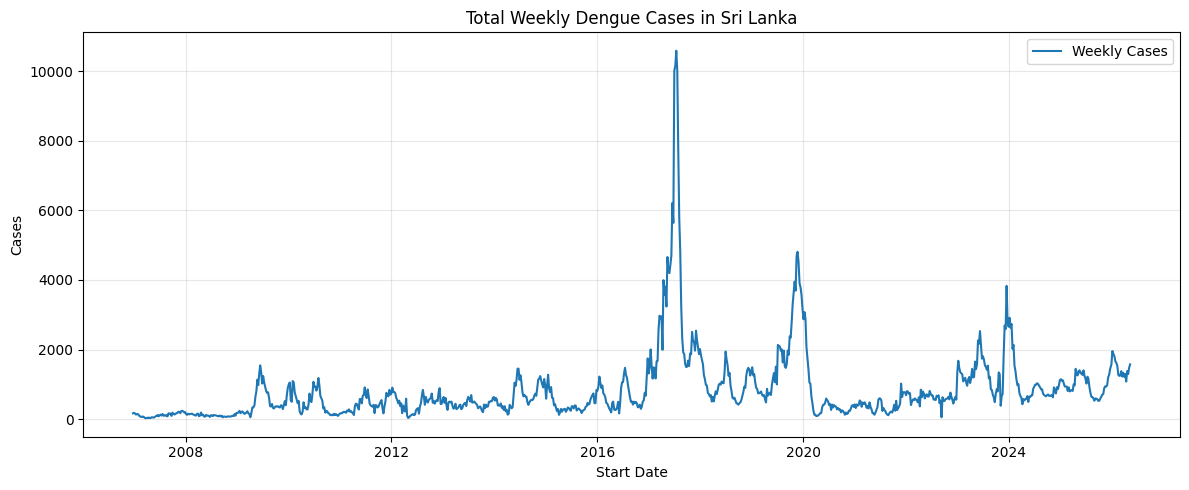

Plot saved: outputs/seasonal_dengue_cases.png


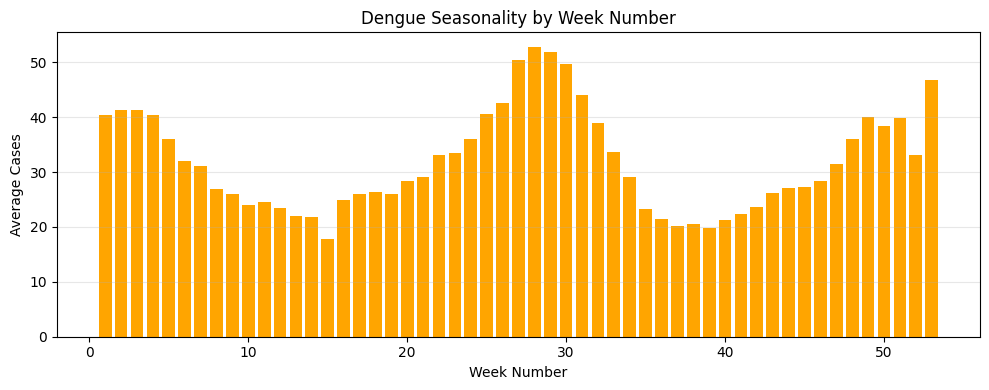


Data shape after filling: (26312, 6)
Null cases after filling: 0

Training data: (25714, 8)
Testing data: (494, 8)
Training years: 2007 - 2025
Testing year: 2026
EBM model training completed.
Model saved: srilanka_dengue_ebm_model.pkl

Model and district thresholds loaded successfully.
Colombo risk threshold: 241.0

Regression Evaluation
---------------------
MAE:  15.19
RMSE: 32.75
R2:   0.8330

Dengue Risk Classification Evaluation
-------------------------------------
Accuracy: 0.7368
Precision: 0.8095
Recall: 0.7846
F1: 0.7969
ROC-AUC: 0.7844

Confusion Matrix
[[109  60]
 [ 70 255]]

District thresholds (75% percentile, saved with the model):
Ampara            4.0
Anuradhapura     13.0
Badulla          19.0
Batticaloa       39.0
Colombo         241.0
Galle            36.0
Gampaha         115.0
Hambanthota      21.0
Jaffna           49.0
Kalmune          16.0
Kalutara         55.0
Kandy            73.0
Kegalle          37.0
Kilinochchi       3.0
Kurunegala       49.0
Mannar        

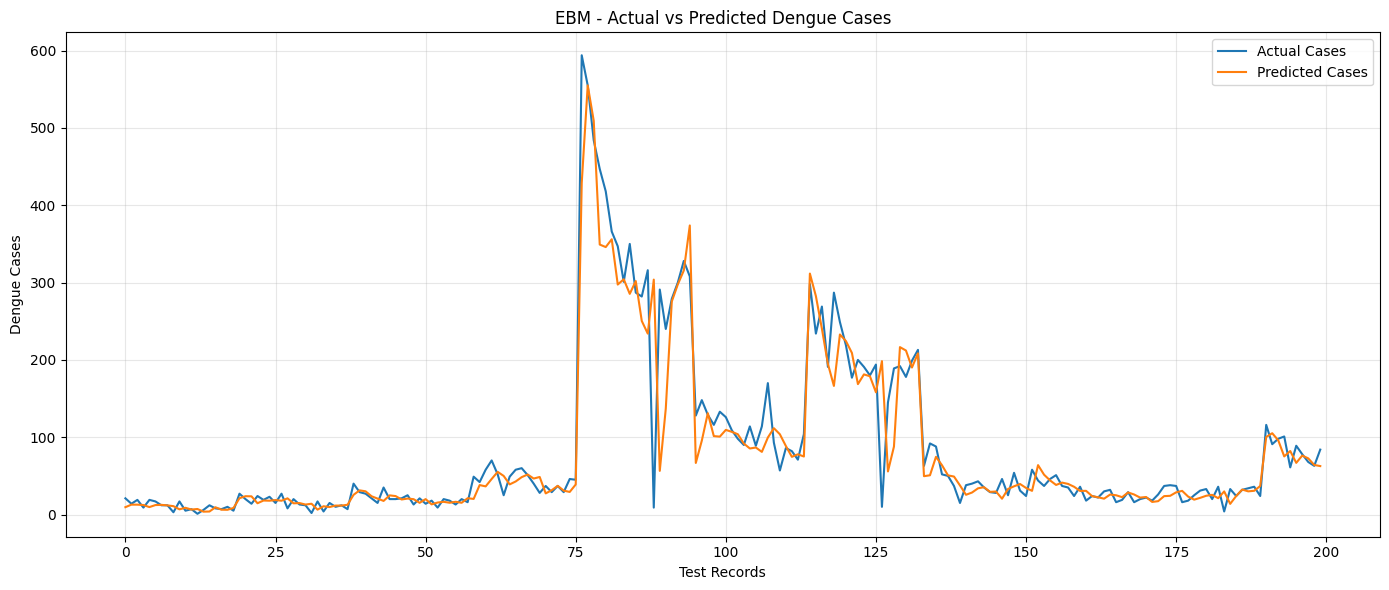


Completed.
Saved model: srilanka_dengue_ebm_model.pkl
Saved plot: outputs/actual_vs_predicted.png


In [2]:
from data_prep import prepare_data
from model_training import train_model
from evaluation import run_evaluation


DATASET_PATH = "srilanka_dengue_weekly_by_district.csv"
MODEL_PATH = "srilanka_dengue_ebm_model.pkl"
PLOT_PATH = "outputs/actual_vs_predicted.png"


def main():
    # Prepare the dataset.
    data = prepare_data(DATASET_PATH)

    # Train and save the model.
    train_model(
        X_train=data["X_train"],
        y_train=data["y_train"],
        train_df=data["train_df"],
        district_categories=data["district_categories"],
        model_path=MODEL_PATH,
        risk_percentile=0.75
    )

    # Evaluate the saved model.
    results = run_evaluation(
        train_df=data["train_df"],
        test_df=data["test_df"],
        X_test=data["X_test"],
        y_test=data["y_test"],
        model_path=MODEL_PATH,
        plot_path=PLOT_PATH,
        risk_percentile=0.75,
    )

    print("\nCompleted.")
    print("Saved model:", MODEL_PATH)
    print("Saved plot:", PLOT_PATH)

    return results


if __name__ == "__main__":
    main()


In [3]:
import pickle
import pandas as pd

with open("srilanka_dengue_ebm_model.pkl", "rb") as file:
    model_data = pickle.load(file)

ebm = model_data["model"]
features = model_data["features"]
feature_types = model_data["feature_types"]
district_categories = model_data["district_categories"]
district_thresholds = model_data["district_thresholds"]

print("Model loaded successfully.")

Model loaded successfully.


In [7]:
new_data = pd.DataFrame([{
    "district_code": district_categories.index("Colombo"),
    "week_sin": 0.5,
    "week_cos": 0.866,
    "cases_lag_1": 120,
    "cases_lag_2": 110,
    "cases_lag_3": 95,
    "cases_lag_4": 100,
    "cases_rolling_avg_4": 106.25
}])

new_data = new_data[features]

In [8]:
predicted_cases = ebm.predict(new_data)[0]

print(f"Predicted dengue cases for next week: {predicted_cases:.0f}")

Predicted dengue cases for next week: 116


In [9]:
district = "Colombo"
threshold = district_thresholds[district]

risk = "High Risk" if predicted_cases >= threshold else "Low Risk"

print("District:", district)
print("Predicted cases:", round(predicted_cases))
print("Risk threshold:", threshold)
print("Risk level:", risk)

District: Colombo
Predicted cases: 116
Risk threshold: 241.0
Risk level: Low Risk


In [6]:
import numpy as np

history = pd.read_csv("srilanka_dengue_weekly_by_district.csv")
history.columns = history.columns.str.strip()
history["start.date"] = pd.to_datetime(history["start.date"])
history = history.sort_values(["district", "start.date"]).reset_index(drop=True)


def build_features(district, week_start):
    """Build one feature row from the 4 weeks of cases up to week_start."""
    if district not in district_categories:
        raise ValueError(f"Unknown district '{district}'. Choose from: {district_categories}")

    week_start = pd.Timestamp(week_start)
    rows = history[(history["district"] == district) & (history["start.date"] <= week_start)]

    if rows.empty:
        raise ValueError(f"No data for {district} on or before {week_start.date()}.")
    if week_start - rows["start.date"].max() > pd.Timedelta(days=6):
        last = history["start.date"].max().date()
        raise ValueError(f"No case data for the week of {week_start.date()}. "
                         f"The dataset ends on {last}; add newer weekly cases to the CSV first.")

    last_4 = rows.tail(4)
    if len(last_4) < 4:
        raise ValueError("Need at least 4 weeks of history before this date.")

    this_week = last_4.iloc[-1]          # the week the user asked for
    cases = last_4["cases"].tolist()     # oldest -> newest

    # same seasonal features as data_prep.create_features
    date = this_week["start.date"]
    days_in_year = 366 if date.is_leap_year else 365
    year_phase = (date.dayofyear - 1) / days_in_year

    row = pd.DataFrame([{
        "district_code": district_categories.index(district),
        "week_sin": np.sin(2 * np.pi * year_phase),
        "week_cos": np.cos(2 * np.pi * year_phase),
        "cases_lag_1": cases[3],     # this week
        "cases_lag_2": cases[2],     # 1 week ago
        "cases_lag_3": cases[1],     # 2 weeks ago
        "cases_lag_4": cases[0],     # 3 weeks ago
        "cases_rolling_avg_4": np.mean(cases),
    }])
    return row[features], date


def predict_next_week(district, week_start):
    """Predict next week's dengue cases from a district and a week start date."""
    X, date = build_features(district, week_start)
    predicted = float(ebm.predict(X)[0])
    threshold = float(district_thresholds[district])
    risk = "HIGH RISK" if predicted >= threshold else "Normal"

    print(f"\n{district} - data week starting {date.date()}")
    print("Last 4 weeks (oldest -> newest):",
          [int(X[c].iloc[0]) for c in ["cases_lag_4", "cases_lag_3", "cases_lag_2", "cases_lag_1"]])
    print(f"Predicted cases next week: {predicted:.0f}")
    print(f"Risk threshold: {threshold:.1f} -> {risk}")

    # if next week is also in the data, show the real value
    next_week = history[(history["district"] == district)
                        & (history["start.date"] == date + pd.Timedelta(days=7))]
    if not next_week.empty:
        print(f"Actual cases next week: {next_week['cases'].iloc[0]:.0f}")

    return {"district": district, "week_start": date.date(),
            "predicted_cases": round(predicted), "threshold": threshold, "risk": risk}

In [7]:
result = predict_next_week("Colombo", "2026-05-04")


Colombo - data week starting 2026-05-04
Last 4 weeks (oldest -> newest): [240, 279, 300, 328]
Predicted cases next week: 374
Risk threshold: 241.0 -> HIGH RISK
Actual cases next week: 308
